# RQ1 analysis — recreational activity profiles across LVVI3, YouTube and Flickr

**Research question.** What recreational practices — single main activities and, more
interestingly, *combinations* of activities — characterize nature-recreation trips in
Finnish state-owned lands, and what does each data source reveal about them?

**Key design insight.** The LVVI3 survey records a *single reported main activity* per
trip. That cannot reveal what else happened during the trip: a walking-oriented trip can
also involve camping, nature observation, dog walking, photography, picnicking, and so
on, and Walking dominates the reported main activities precisely because it is how most
trips are *primarily* characterized, not because trips consist only of walking. The two
sources therefore answer **complementary questions**:

- **Level 1 — LVVI3 survey: what *main activities* characterize recreational trips?**
  Descriptive characterization of the reported main activity only. No latent class
  analysis is fitted on the survey: with one main activity per trip, combinations
  cannot be observed.
- **Level 2 — YouTube & Flickr: what *activity compositions* are documented within
  nature trips?** Latent class analysis (LCA) on episode-level activity indicators
  derived from Clef model probabilities, fitted separately per source.

**Important qualification (applies throughout).** LVVI3 gives the *reported main
activity*, not everything that occurred on the trip; social media shows the activities
*documented* in the produced content, not a complete record of the trip. The analyses
below investigate what each source reveals rather than assuming any source is a
complete account of recreational behaviour.

**Inputs**

- `data/LVVI3/lvvi3_survey_en.csv` — LVVI3 survey table (451 trips; `activity` = reported main activity)
- `data/activity_categorization.csv` — activity → 9 activity categories
- `data/YouTube/clef_labels/clef_full.shard_*.jsonl` — per-video Clef activity probabilities (3,745 videos)
- `data/Flickr/clef_labels/flickr_clef.shard_*.jsonl` — per-photo Clef activity probabilities (16,773 photos)
- `data/Flickr/flickr_trips.gpkg` — Flickr photo trips (669 trips; 24 h gap rule)
- `data/YouTube/clef_labels/youtube_clef_videos_wide.csv` — per-video metadata (dates, area flags, geometry)

**Outputs:** none — analysis only; produces no pipeline artifacts (figures inline only).

## 1. Setup

Latent class models are Bernoulli LCA fitted with `stepmix`, from multiple random
starts, keeping the solution with the highest log-likelihood. The 0.5 probability
threshold for turning Clef probabilities into binary activity indicators follows the
project's `labels_at_0.5` convention used in the per-video / per-photo label tables.

In [1]:
import ast
import glob
import json
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shapely.wkt
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import pairwise_distances
from stepmix import StepMix

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

DATA = "../../data"

# LCA settings: k range, seeds for the model-selection scan, seeds for the final refit
K_RANGE = range(2, 9)
N_SEEDS = 5
N_SEEDS_FINAL = 20
THRESHOLD = 0.5          # Clef probability -> binary indicator (project labels_at_0.5 convention)
MIN_PREVALENCE = 0.01    # keep indicators documented in >=1% of a source's episodes

# Chosen number of classes per source (justified from the fit tables in section 3)
CHOSEN_K = {"YouTube": 6, "Flickr": 5}

# Meteorological seasons by month
SEASONS = {12: "Winter", 1: "Winter", 2: "Winter",
           3: "Spring", 4: "Spring", 5: "Spring",
           6: "Summer", 7: "Summer", 8: "Summer",
           9: "Autumn", 10: "Autumn", 11: "Autumn"}
SEASON_ORDER = ["Spring", "Summer", "Autumn", "Winter"]
AREA_FLAGS = ["national_park", "nature_reserve", "wilderness_area", "commercial_forest"]
AREA_LABELS = {"national_park": "National park", "nature_reserve": "Nature reserve",
               "wilderness_area": "Wilderness area", "commercial_forest": "Commercial forest"}
print("setup done")

setup done


## 2. Step 1 — LVVI3: profile of the *reported main activity* (Level 1, descriptive)

The survey answers: **what main activities characterize recreational trips in Finland?**
Each of the 451 survey rows is one reported trip with a single main activity
(`activity`, with `sub_activity` detail, survey weight
`paino2_weight`, and participant source `source` ∈ {nbt, or}). Activities are mapped to
the nine activity categories of `data/activity_categorization.csv`. Activity renames
(Forest → Nature management, Plant → Gardening, applied 2026-10-20) should already be
reflected in the survey table; this is verified by assertion rather than silently
dropping unmatched values.

No LCA is fitted here: a single main activity per trip cannot reveal activity
*combinations*. The composition question is taken up in Steps 2–4 with the social-media
sources. The survey weight `paino2_weight` exists; for simplicity the tables below are
**unweighted**, with a weighted comparison shown as a robustness note.

In [2]:
df_survey = pd.read_csv(f"{DATA}/LVVI3/lvvi3_survey_en.csv")
cat_map = pd.read_csv(f"{DATA}/activity_categorization.csv")

print(f"survey shape: {df_survey.shape}")
df_survey = df_survey.dropna(subset=["activity"])
print(f"rows with a reported main activity: {len(df_survey)}")

# Map the 35 activities to the nine activity categories; verify (not silently drop)
activity_to_cat = dict(zip(cat_map["activity"], cat_map["activity_category"]))
unmatched = sorted(set(df_survey["activity"]) - set(activity_to_cat))
assert not unmatched, f"survey activities missing from categorization: {unmatched}"
df_survey["activity_category"] = df_survey["activity"].map(activity_to_cat)

print("\nsource x activity_category:")
print(pd.crosstab(df_survey["source"], df_survey["activity_category"]).to_string())

# --- activity-category infrastructure used by the profile heatmaps below ---
# Nine categories, in CSV first-appearance order; within-category order = CSV row order.
CATEGORY_ORDER = list(dict.fromkeys(cat_map["activity_category"]))
activity_by_cat = {cat: cat_map.loc[cat_map["activity_category"] == cat, "activity"].tolist()
                   for cat in CATEGORY_ORDER}
CATEGORY_PALETTE = {
    "Land-based recreation": "#1f77b4",
    "Snow and ice recreation": "#17becf",
    "Water-based recreation": "#2ca02c",
    "Motorised recreation": "#8c564b",
    "Consumptive interaction": "#bcbd22",
    "Nature appreciation": "#9467bd",
    "Leisure and social activities": "#e377c2",
    "Nature-based stays": "#ff7f0e",
    "Nature and land management": "#7f7f7f",
}

def grouped_columns(activities):
    """Order activities by category (CSV within-category order).
    Returns (ordered_activities, category_per_activity)."""
    acts = set(activities)
    ordered, cats = [], []
    for cat in CATEGORY_ORDER:
        a = [x for x in activity_by_cat[cat] if x in acts]
        ordered.extend(a)
        cats.extend([cat] * len(a))
    return ordered, cats

survey shape: (451, 132)
rows with a reported main activity: 451

source x activity_category:
activity_category  Consumptive interaction  Land-based recreation  Leisure and social activities  Motorised recreation  Nature and land management  Nature appreciation  Nature-based stays  Snow and ice recreation  Water-based recreation
source                                                                                                                                                                                                                                      
nbt                                     28                    165                             16                     3                           1                   14                  14                       30                      15
or                                      14                    121                              7                     3                           0                    5                   3        

,n,share
activity_category,,
Land-based recreation,286,0.634
Consumptive interaction,42,0.093
Snow and ice recreation,41,0.091
Leisure and social activities,23,0.051
Nature appreciation,19,0.042
Nature-based stays,17,0.038
Water-based recreation,16,0.035
Motorised recreation,6,0.013
Nature and land management,1,0.002


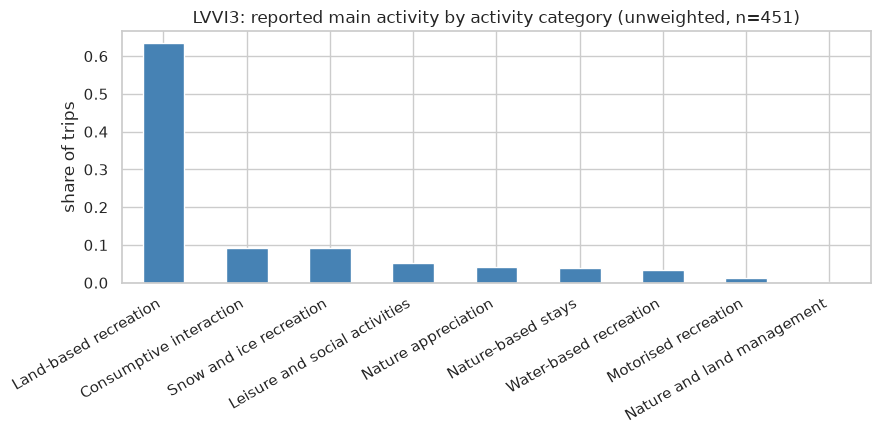

In [3]:
# (a) Nine aggregated activity categories
cat_order = (df_survey["activity_category"].value_counts().index.tolist())
tab_cat = (df_survey["activity_category"].value_counts().rename_axis("activity_category")
           .to_frame("n").assign(share=lambda d: (d["n"] / d["n"].sum()).round(3)))
display(tab_cat)

fig, ax = plt.subplots(figsize=(9, 4.5))
tab_cat["share"].reindex(cat_order).plot.bar(ax=ax, color="steelblue")
ax.set_ylabel("share of trips"); ax.set_xlabel("")
ax.set_title("LVVI3: reported main activity by activity category (unweighted, n=451)")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

,n,share
activity,,
Walking,219,0.525
Skiing,40,0.096
Dog walking,25,0.060
Fishing,23,0.055
Cycling,17,0.041
Boating,14,0.034
Hunting,12,0.029
Running,12,0.029
Nature observation,11,0.026


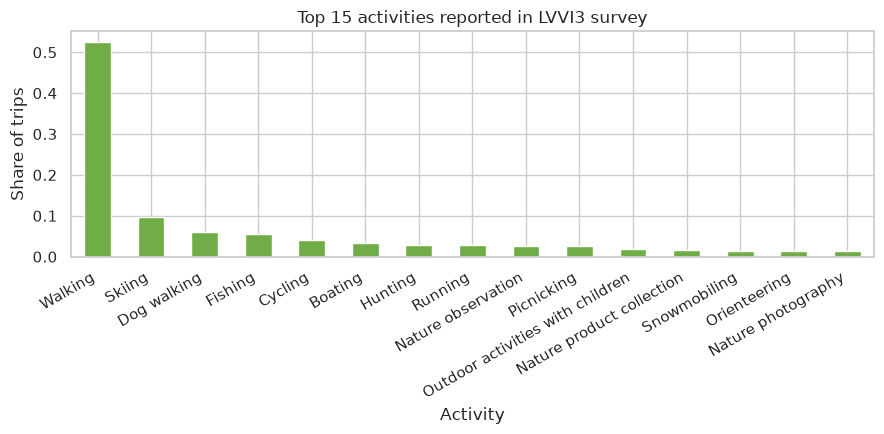

Walking share of main activities: unweighted 48.6%, weighted 47.7%
Note: survey weights change levels slightly; unweighted shares are reported below for simplicity.


In [4]:
# (b) Detailed activities (top 15)
tab_act = (df_survey["activity"].value_counts().head(15).rename_axis("activity")
           .to_frame("n").assign(share=lambda d: (d["n"] / d["n"].sum()).round(3)))
display(tab_act)

fig, ax = plt.subplots(figsize=(9, 4.5))
tab_act["share"].plot.bar(ax=ax, color="#70AD47")
ax.set_ylabel("Share of trips"); ax.set_xlabel("Activity")
ax.set_title("Top 15 activities reported in LVVI3 survey")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

# Weighted robustness note (survey weight paino2_weight)
w = df_survey["paino2_weight"]
walk_u = (df_survey["activity"] == "Walking").mean()
walk_w = np.average(df_survey["activity"] == "Walking", weights=w)
print(f"Walking share of main activities: unweighted {walk_u:.1%}, weighted {walk_w:.1%}")
print("Note: survey weights change levels slightly; unweighted shares are reported below for simplicity.")

**Reading.** Walking is by far the most frequently reported main activity
(~half of trips), followed at a distance by skiing, dog walking, fishing and cycling.
A main-activity view is therefore dominated by *how the trip is primarily
characterized*, and says little about what else the trip involved — e.g. a
walking-oriented trip may also include camping, nature observation, dog walking or
photography. This dominance is the motivation for Level 2: characterizing the
*documented activity composition* of trips from social media, including trips whose
primary activity is walking. (The user's Walking+dog walking / Walking+camping /
Walking+photography examples are illustrative only; the profiles below are derived
empirically from the data.)

## 3. Step 2 — Episode-level activity indicators from Clef probabilities

**Episodes.** YouTube episode = one video (3,745 Clef-labeled NBT videos in state-owned
lands). Flickr episode = one photo trip (669 trips in `flickr_trips.gpkg`, built with a
24 h gap rule; the on-disk trip files are kept from the earlier labeling run by project
decision, and *all* trip photos are covered by the Clef labels — verified below by a
100% id overlap).

**Indicators.** Each Clef record gives per-activity probabilities over exactly the 35
LVVI3 survey activities (verified equal to `data/LVVI3/LVVI3_activities.csv`). A binary
indicator is `p >= 0.5`, the threshold already used by the project's `labels_at_0.5`
label convention.

- YouTube: video × 35 probability matrix → video × 35 indicators.
- Flickr: trip-level activity score = **max** of the activity's probability over the
  trip's photos (a trip documents an activity if *any* of its photos shows it), then
  thresholded at 0.5 → trip × 35 indicators.

Raw probability matrices are retained for the threshold sensitivity analysis at the end
of this section.

In [5]:
# --- YouTube: video x 35 probabilities ---
yt_probs_dict = {}
for f in sorted(glob.glob(f"{DATA}/YouTube/clef_labels/clef_full.shard_*.jsonl")):
    for line in open(f):
        d = json.loads(line)
        yt_probs_dict[d["video_id"]] = d["probabilities"]
df_yt_probs = pd.DataFrame(yt_probs_dict).T.sort_index()
assert df_yt_probs.shape[1] == 35 and df_yt_probs.notna().all().all()
df_yt_ind = (df_yt_probs >= THRESHOLD).astype(int)
print(f"YouTube episodes: {df_yt_ind.shape[0]} videos x {df_yt_ind.shape[1]} activity indicators")

# --- Flickr: photo x 35 probabilities ---
fl_probs_dict = {}
for f in sorted(glob.glob(f"{DATA}/Flickr/clef_labels/flickr_clef.shard_*.jsonl")):
    for line in open(f):
        d = json.loads(line)
        fl_probs_dict[d["id"]] = d["probabilities"]   # later shard wins on duplicate ids
df_fl_photo_probs = pd.DataFrame(fl_probs_dict).T
print(f"Flickr labeled photos: {df_fl_photo_probs.shape[0]} x {df_fl_photo_probs.shape[1]}")

# --- Flickr trips: trip-level score = max photo probability per activity ---
gdf_trips = gpd.read_file(f"{DATA}/Flickr/flickr_trips.gpkg")
gdf_trips["img_list"] = gdf_trips["image_ids"].map(ast.literal_eval)
trip_photos = gdf_trips.groupby("trip_id")["img_list"].agg(lambda s: set().union(*s))

trip_rows = []
for trip_id, imgs in trip_photos.items():
    ids = [str(i) for i in imgs]
    missing = [i for i in ids if i not in df_fl_photo_probs.index]
    assert not missing, f"trip {trip_id}: {len(missing)} photos without Clef labels"
    trip_rows.append(pd.Series(df_fl_photo_probs.loc[ids].max(axis=0), name=trip_id))
df_fl_probs = pd.DataFrame(trip_rows).sort_index()
df_fl_ind = (df_fl_probs >= THRESHOLD).astype(int)
print(f"Flickr episodes: {df_fl_ind.shape[0]} trips x {df_fl_ind.shape[1]} activity indicators "
      f"(all {sum(len(v) for v in trip_photos)} trip photos Clef-labeled)")

YouTube episodes: 3745 videos x 35 activity indicators


Flickr labeled photos: 15813 x 35


Flickr episodes: 669 trips x 35 activity indicators (all 3171 trip photos Clef-labeled)


### Diagnostics and indicator restriction

An episode can have *zero* positively documented activities (no evidence above the
threshold). For LCA stability, indicators are restricted per source to activities
documented in at least 1% of that source's episodes (documented choice; the full 35-item
matrices are kept for descriptive co-occurrence).

In [6]:
def diagnostics(df_ind, name):
    zero = (df_ind.sum(axis=1) == 0)
    prev = df_ind.mean().sort_values(ascending=False)
    print(f"{name}: {df_ind.shape[0]} episodes; zero-evidence episodes: {zero.sum()} "
          f"({zero.mean():.1%}); mean documented activities/episode: {df_ind.sum(axis=1).mean():.1f}")
    return prev

prev_yt = diagnostics(df_yt_ind, "YouTube")
prev_fl = diagnostics(df_fl_ind, "Flickr")
keep_yt = prev_yt[prev_yt >= MIN_PREVALENCE].index.tolist()
keep_fl = prev_fl[prev_fl >= MIN_PREVALENCE].index.tolist()
print(f"\nrestricted indicator sets (>=1% of episodes): YouTube {len(keep_yt)}, Flickr {len(keep_fl)}")
print("kept only in YouTube:", sorted(set(keep_yt) - set(keep_fl)))
print("kept only in Flickr:", sorted(set(keep_fl) - set(keep_yt)))
print("\nTop-10 documented activities per source (share of episodes):")
display(pd.DataFrame({"YouTube": prev_yt.head(10).round(3), "Flickr": prev_fl.head(10).round(3)}))

YouTube: 3745 episodes; zero-evidence episodes: 150 (4.0%); mean documented activities/episode: 3.1
Flickr: 669 episodes; zero-evidence episodes: 0 (0.0%); mean documented activities/episode: 2.2

restricted indicator sets (>=1% of episodes): YouTube 26, Flickr 24
kept only in YouTube: ['Flying a drone', 'Running', 'Treasure hunting']
kept only in Flickr: ['Nature management']

Top-10 documented activities per source (share of episodes):


,YouTube,Flickr
Boating,0.095,0.211
Camping,0.276,0.161
Cycling,0.089,NaN
Dog walking,NaN,0.063
Nature observation,0.442,0.338
Nature photography,0.249,0.108
Outdoor activities with children,NaN,0.118
Skiing,0.150,0.175
Sledding,0.114,0.067
"Staying in a summer cottage, farm, holiday home",0.149,NaN


In [7]:
# Threshold sensitivity: rebuild indicators at 0.3 / 0.5 / 0.7
rows = []
for t in [0.3, 0.5, 0.7]:
    for name, df_p in [("YouTube", df_yt_probs), ("Flickr", df_fl_probs)]:
        X = (df_p >= t).astype(int)
        rows.append({"source": name, "threshold": t,
                     "mean_activities_per_episode": round(X.sum(axis=1).mean(), 2),
                     "zero_evidence_share": round((X.sum(axis=1) == 0).mean(), 3)})
tab_sens = pd.DataFrame(rows).pivot(index="threshold", columns="source",
                                    values=["mean_activities_per_episode", "zero_evidence_share"])
display(tab_sens)
print("Higher thresholds reduce documented activities per episode and raise the zero-evidence share;")
print("the 0.5 convention is retained as the main analysis; probability matrices are kept for sensitivity.")

mean_activities_per_episode         zero_evidence_share        
source                         Flickr YouTube              Flickr YouTube
threshold                                                                
0.3                              6.51    9.55               0.000   0.006
0.5                              2.24    3.14               0.000   0.040
0.7                              1.02    1.64               0.278   0.147

Higher thresholds reduce documented activities per episode and raise the zero-evidence share;
the 0.5 convention is retained as the main analysis; probability matrices are kept for sensitivity.


## 4. Step 3 — Activity-composition profiles via LCA (per source, separately)

Bernoulli LCA (`StepMix`) is fitted **separately per source** on the restricted
indicator sets, for k = 2..8, `N_SEEDS` random starts each, keeping the best
log-likelihood. Model selection uses, jointly:

1. **BIC** (lower is better) — primary statistical criterion;
2. **minimum class share ≥ ~5%** — no de facto residual classes;
3. **interpretability** — profiles that correspond to substantively meaningful
   activity combinations;
4. **stability** — the best-of-20-seeds refit at the chosen k.

k is chosen **empirically per source**; the two sources are not forced to the same k.
Note the class indices of the two models are NOT comparable (separate fits) — Step 4
matches profiles by their activity-probability structure.

In [8]:
def entropy_r2(resp):
    """Entropy R^2 from a posterior responsibility matrix (1 = perfect separation)."""
    ent = -(resp * np.log(np.clip(resp, 1e-12, 1))).sum(axis=1)
    return float(1 - ent.mean() / np.log(resp.shape[1]))


def fit_lca_best(X, k, n_seeds):
    """Fit Bernoulli LCA from n_seeds random starts; return the best-log-likelihood model."""
    best, best_ll = None, -np.inf
    for s in range(n_seeds):
        m = StepMix(n_components=k, measurement="bernoulli", random_state=s,
                    max_iter=1000, verbose=0, progress_bar=0)
        m.fit(X)
        if m.score(X) > best_ll:
            best, best_ll = m, m.score(X)
    return best


def fit_table(X, ks, n_seeds):
    rows = []
    for k in ks:
        m = fit_lca_best(X, k, n_seeds)
        resp = m.predict_proba(X)
        shares = resp.mean(axis=0)
        rows.append({"k": k, "logLik": round(m.score(X), 1), "AIC": round(m.aic(X), 1),
                     "BIC": round(m.bic(X), 1), "entropy_R2": round(entropy_r2(resp), 3),
                     "min_class_share": round(shares.min(), 3)})
    return pd.DataFrame(rows)


X_yt = df_yt_ind[keep_yt].to_numpy()
X_fl = df_fl_ind[keep_fl].to_numpy()
tab_fit_yt = fit_table(X_yt, K_RANGE, N_SEEDS)
tab_fit_fl = fit_table(X_fl, K_RANGE, N_SEEDS)
print("YouTube fit table (per-video indicators, best of "
      f"{N_SEEDS} seeds):"); display(tab_fit_yt)
print("Flickr fit table (per-trip indicators, best of "
      f"{N_SEEDS} seeds):"); display(tab_fit_fl)

YouTube fit table (per-video indicators, best of 5 seeds):


,k,logLik,AIC,BIC,entropy_R2,min_class_share
0,2,-7.1,53369.0,53699.0,0.935,0.330
1,3,-7.0,52267.9,52766.1,0.820,0.257
2,4,-6.8,51415.2,52081.6,0.813,0.138
3,5,-6.8,50966.6,51801.2,0.834,0.094
4,6,-6.7,50568.2,51571.0,0.841,0.054
5,7,-6.7,50336.1,51507.0,0.863,0.022
6,8,-6.6,50140.9,51480.0,0.831,0.022


Flickr fit table (per-trip indicators, best of 5 seeds):


,k,logLik,AIC,BIC,entropy_R2,min_class_share
0,2,-5.6,7595.0,7815.8,0.884,0.175
1,3,-5.4,7343.3,7676.7,0.953,0.082
2,4,-5.2,7159.3,7605.3,0.891,0.075
3,5,-5.1,7044.5,7603.2,0.902,0.076
4,6,-5.0,6994.4,7665.8,0.878,0.074
5,7,-4.9,6944.3,7728.3,0.891,0.025
6,8,-4.9,6937.4,7834.1,0.906,0.035


**Model selection.**

- **YouTube**: BIC decreases through k = 8, but the k = 7 and k = 8 solutions contain
  classes of ~2–5% and ~2% of videos — de facto residual classes below the ~5% rule —
  while k = 6 keeps all classes ≥ 5% with an essentially identical fit quality. **k = 6
  is chosen.**
- **Flickr**: BIC reaches its minimum at **k = 5** (7,603; k = 6 is worse at 7,666 and
  k ≥ 7 introduces ~2% classes). All five classes exceed 7%. **k = 5 is chosen.**

The chosen models are refit with `N_SEEDS_FINAL = 20` seeds below.

In [9]:
model_yt = fit_lca_best(X_yt, CHOSEN_K["YouTube"], N_SEEDS_FINAL)
model_fl = fit_lca_best(X_fl, CHOSEN_K["Flickr"], N_SEEDS_FINAL)

def lca_results(model, X, keep, name):
    resp = model.predict_proba(X)
    pred = model.predict(X)
    shares = pd.Series(resp.mean(axis=0)).sort_values(ascending=False)
    order = shares.index.to_numpy()              # classes renumbered by prevalence
    # Exact M-step solution, columns in X order (avoids get_mm_df feature-name ordering issues)
    rho = pd.DataFrame((resp.T @ X) / resp.sum(axis=0)[:, None], columns=keep)
    # Sanity: rho must reproduce the observed per-class endorsement rates (modal assignment)
    obs = np.array([X[pred == c].mean(axis=0) for c in range(model.n_components)])
    max_gap = np.abs(rho.to_numpy() - obs).max()
    assert max_gap < 0.15, f"{name}: rho inconsistent with observed class-conditional rates (gap {max_gap:.2f})"
    rho = rho.iloc[order]                        # rows now ordered by prevalence
    rho.index = [f"P{j+1}" for j in range(len(order))]
    shares.index = rho.index
    rank_of = {int(c): r for r, c in enumerate(order)}   # original class id -> prevalence rank
    pred_rank = pd.Series(pred).map(rank_of).to_numpy()
    return {"model": model, "resp": resp, "X": X, "keep": keep,
            "pred": pred_rank, "shares": shares, "rho": rho}

res_yt = lca_results(model_yt, X_yt, keep_yt, "YouTube")
res_fl = lca_results(model_fl, X_fl, keep_fl, "Flickr")
for name, res in [("YouTube", res_yt), ("Flickr", res_fl)]:
    print(f"{name}: chosen k={res['rho'].shape[0]}, BIC={res['model'].bic(X_yt if name=='YouTube' else X_fl):.1f}, "
          f"entropy R2={entropy_r2(res['resp']):.3f}")
    print("class prevalences:", res["shares"].round(3).to_dict())

YouTube: chosen k=6, BIC=51571.0, entropy R2=0.841
class prevalences: {'P1': 0.334, 'P2': 0.227, 'P3': 0.196, 'P4': 0.095, 'P5': 0.093, 'P6': 0.054}
Flickr: chosen k=5, BIC=7603.2, entropy R2=0.902
class prevalences: {'P1': 0.377, 'P2': 0.288, 'P3': 0.166, 'P4': 0.094, 'P5': 0.076}


### Local independence check

LCA assumes local (conditional) independence of the indicators within class. As a
diagnostic, for each class and item pair the observed class-conditional co-endorsement
is compared with the independence expectation `rho_ci * rho_cj`; the largest
standardized residuals are reported as a caveat. In both sources the largest residuals
are modest (max |z| ≈ 0.5 for YouTube, ≈ 1.0 for Flickr), i.e. no strong local
independence violations remain within profiles — the classes account for the pairwise
structure in the indicator sets.

In [10]:
def top_residuals(res, top_n=12):
    """Largest class-conditional standardized residual associations (observed vs independence-expected)."""
    model, X, keep = res["model"], res["X"], res["keep"]
    rho = res["rho"].to_numpy()                       # classes ordered by prevalence (P1..Pk)
    resp, pred = res["resp"], res["pred"]
    out = []
    for rank in range(rho.shape[0]):
        Xc = X[pred == rank]
        n_c = len(Xc)
        for i in range(len(keep)):
            for j in range(i + 1, len(keep)):
                obs = Xc[:, i] @ Xc[:, j] / n_c
                exp = rho[rank, i] * rho[rank, j]
                se = np.sqrt(max(exp * (1 - exp), 1e-12))
                out.append({"profile": f"P{rank+1}", "activity_1": keep[i], "activity_2": keep[j],
                            "observed": round(obs, 3), "expected": round(exp, 3),
                            "z": round((obs - exp) / se, 1)})
    df = pd.DataFrame(out)
    return df.reindex(df["z"].abs().sort_values(ascending=False).index).head(top_n)

print("YouTube (largest |z| class-conditional residual associations):")
display(top_residuals(res_yt))
print("Flickr (largest |z| class-conditional residual associations):")
display(top_residuals(res_fl))

YouTube (largest |z| class-conditional residual associations):


,profile,activity_1,activity_2,observed,expected,z
1920,P6,Swimming,Running,0.011,0.000,0.5
1155,P4,Boating,Swimming,0.057,0.010,0.5
1027,P4,"Staying overnight in a tent, lodge, etc. in na...","Staying in a summer cottage, farm, holiday home",0.304,0.155,0.4
1384,P5,Camping,Travelling or staying in a caravan or camper,0.027,0.003,0.4
1741,P6,Skiing,Sledding,0.228,0.136,0.3
176,P1,Boating,Fishing,0.033,0.007,0.3
1801,P6,Boating,Fishing,0.021,0.004,0.3
1179,P4,Cycling,Climbing,0.003,0.000,0.3
1919,P6,Swimming,Treasure hunting,0.011,0.001,0.3
1586,P5,Travelling or staying in a caravan or camper,Treasure hunting,0.007,0.001,0.3


Flickr (largest |z| class-conditional residual associations):


,profile,activity_1,activity_2,observed,expected,z
744,P3,"Staying in a summer cottage, farm, holiday home",Travelling or staying in a caravan or camper,0.009,0.000,1.0
1262,P5,Sledding,Snowmobiling,0.220,0.073,0.6
947,P4,Outdoor activities with children,Swimming,0.016,0.001,0.6
556,P3,Walking,Outdoor activities with children,0.018,0.001,0.5
1169,P5,Boating,Guided tour,0.080,0.022,0.4
1060,P4,Picnicking,Nature product collection,0.016,0.002,0.4
1187,P5,Skiing,Skating,0.100,0.028,0.4
1365,P5,Travelling or staying in a caravan or camper,Nature management,0.060,0.013,0.4
941,P4,Outdoor activities with children,Picnicking,0.016,0.001,0.4
1161,P5,Boating,Bird watching,0.040,0.012,0.3


### Profile interpretation

Class-conditional endorsement probabilities (rho) for the chosen models, classes ordered
by prevalence (P1 = most prevalent). Profiles are named substantively from their most
strongly endorsed activities. The names describe the *documented* activity composition
of episodes assigned to each class — not established trip types.
An aggregated **category-level** view follows each activity-level heatmap: for every
profile and category, the probability that *at least one* activity of the category is
documented, computed as 1 − ∏(1 − ρ_a) over that category's activities in the model's
restricted indicator set. This is exact if conditional independence holds within a
profile; activities dropped by the ≥1% restriction make it a slight lower bound. The
activity-level heatmap remains the primary view — the category heatmap is an aggregation
of it, not a replacement.


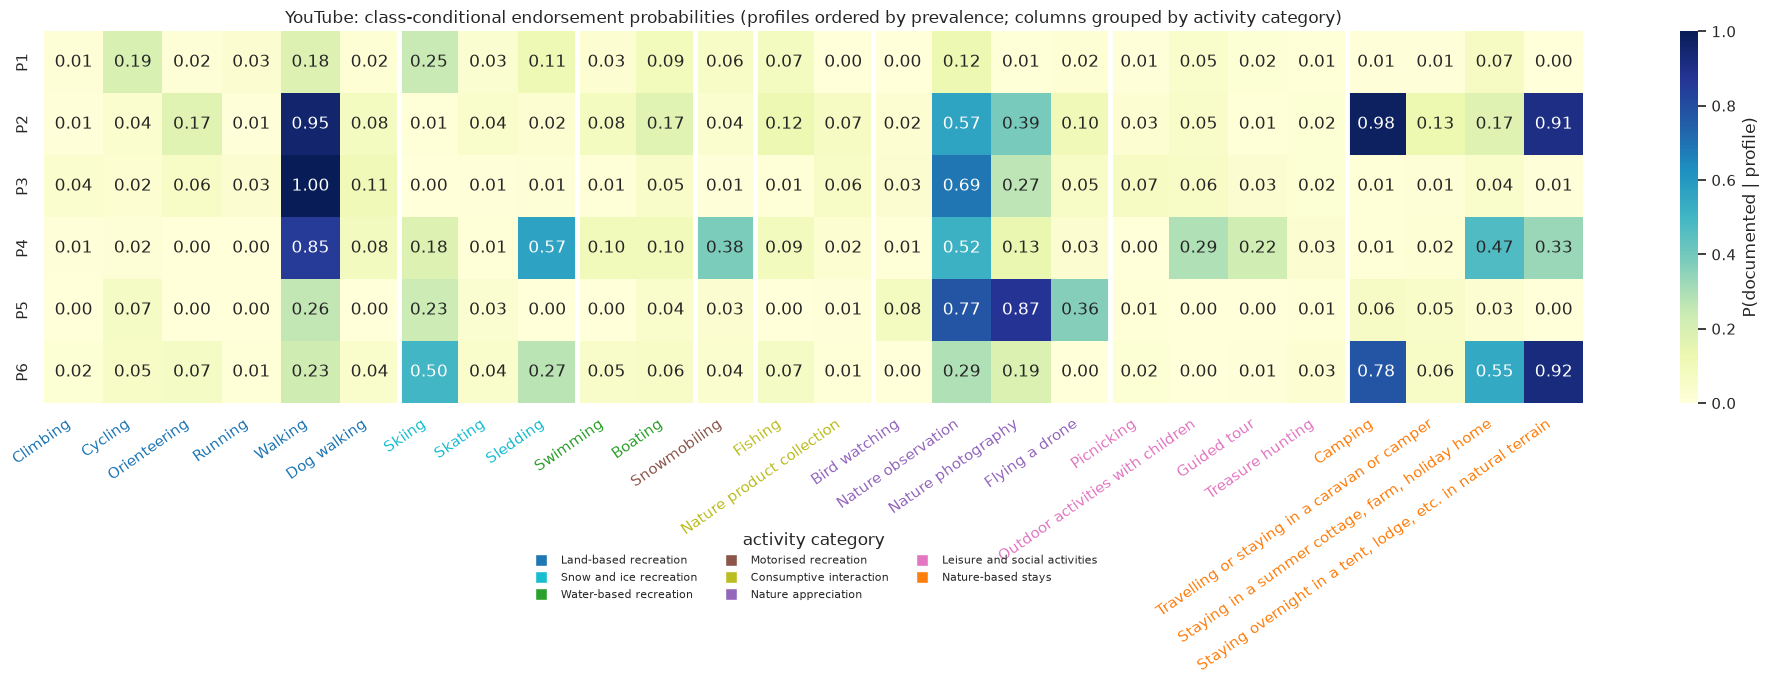

YouTube — endorsement probabilities >= 0.10:
  P1 (prevalence 33.4%): Skiing (0.25), Cycling (0.19), Walking (0.18), Nature observation (0.12), Sledding (0.11)
  P2 (prevalence 22.7%): Camping (0.98), Walking (0.95), Staying overnight in a tent, lodge, etc. in natural terrain (0.91), Nature observation (0.57), Nature photography (0.39), Staying in a summer cottage, farm, holiday home (0.17), Orienteering (0.17), Boating (0.17), Travelling or staying in a caravan or camper (0.13), Fishing (0.12), Flying a drone (0.10)
  P3 (prevalence 19.6%): Walking (1.00), Nature observation (0.69), Nature photography (0.27), Dog walking (0.11)
  P4 (prevalence 9.5%): Walking (0.85), Sledding (0.57), Nature observation (0.52), Staying in a summer cottage, farm, holiday home (0.47), Snowmobiling (0.38), Staying overnight in a tent, lodge, etc. in natural terrain (0.33), Outdoor activities with children (0.29), Guided tour (0.22), Skiing (0.18), Nature photography (0.13), Swimming (0.10), Boating (0.10)

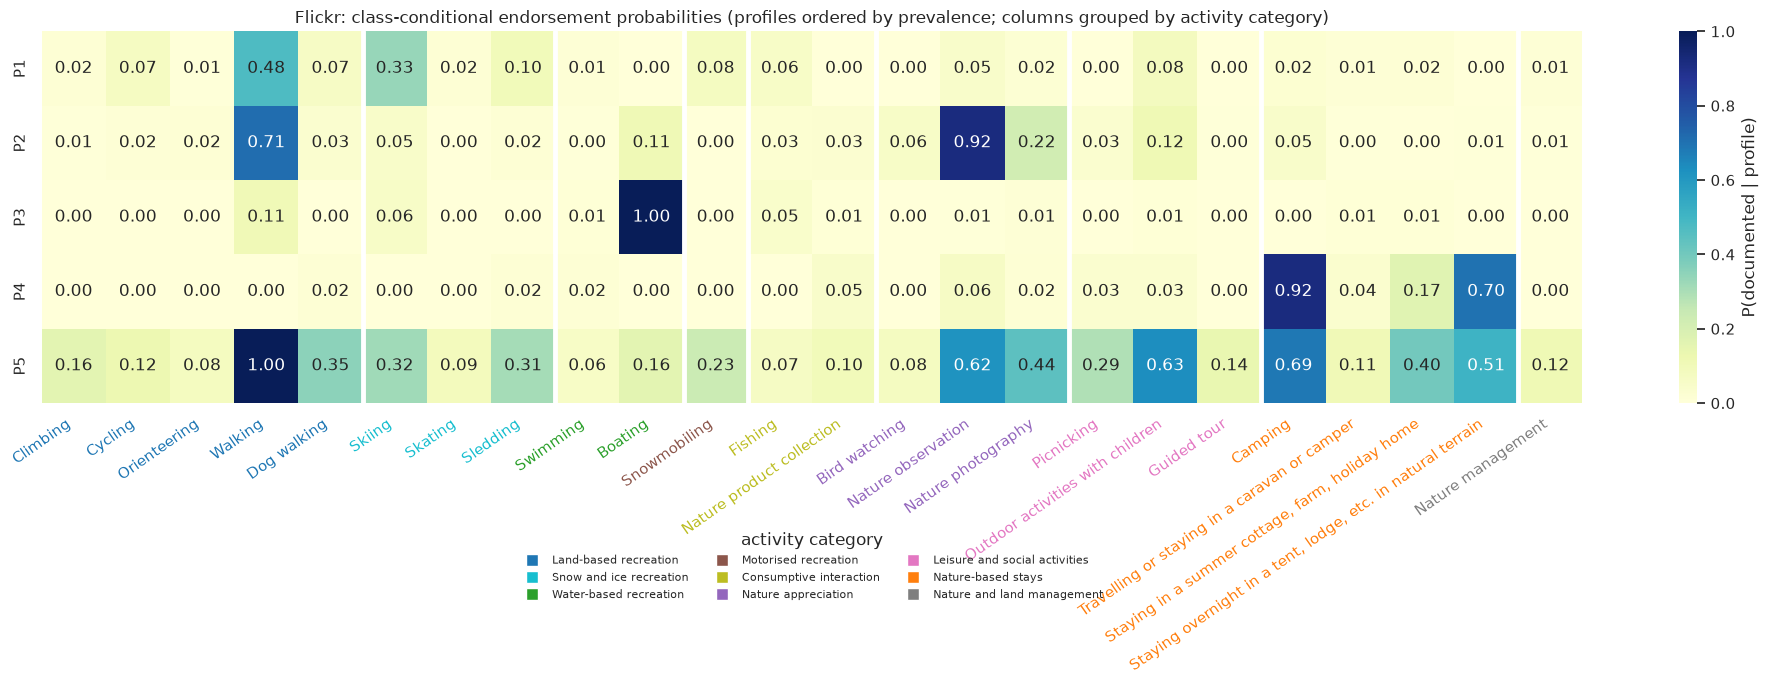

Flickr — endorsement probabilities >= 0.10:
  P1 (prevalence 37.7%): Walking (0.48), Skiing (0.33)
  P2 (prevalence 28.8%): Nature observation (0.92), Walking (0.71), Nature photography (0.22), Outdoor activities with children (0.12), Boating (0.11)
  P3 (prevalence 16.6%): Boating (1.00), Walking (0.11)
  P4 (prevalence 9.4%): Camping (0.92), Staying overnight in a tent, lodge, etc. in natural terrain (0.70), Staying in a summer cottage, farm, holiday home (0.17)
  P5 (prevalence 7.6%): Walking (1.00), Camping (0.69), Outdoor activities with children (0.63), Nature observation (0.62), Staying overnight in a tent, lodge, etc. in natural terrain (0.51), Nature photography (0.44), Staying in a summer cottage, farm, holiday home (0.40), Dog walking (0.35), Skiing (0.32), Sledding (0.31), Picnicking (0.29), Snowmobiling (0.23), Climbing (0.16), Boating (0.16), Guided tour (0.14), Cycling (0.12), Nature management (0.12), Travelling or staying in a caravan or camper (0.11)


In [11]:
def plot_rho_grouped(rho, title, ax=None, figsize=(20, 7), cbar=True):
    """Rho heatmap with activity columns grouped by the nine categories:
    thick white separators at category boundaries, x-tick labels colored by
    category, and a category-color legend below the plot."""
    ordered, cats = grouped_columns(rho.columns)
    r = rho[ordered]
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(r, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax,
                cbar=cbar, cbar_kws={"label": "P(documented | profile)"} if cbar else None)
    for b in range(1, len(ordered)):
        if cats[b] != cats[b - 1]:
            ax.axvline(b, color="white", lw=3.5)
    for tick, cat in zip(ax.get_xticklabels(), cats):
        tick.set_color(CATEGORY_PALETTE[cat])
        tick.set_rotation(35)
        tick.set_ha("right")
    ax.set_title(title)
    ax.set_xlabel("")
    handles = [plt.Line2D([0], [0], marker="s", color="w", markerfacecolor=CATEGORY_PALETTE[cat],
                          markersize=9, label=cat) for cat in CATEGORY_ORDER if cat in set(cats)]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.32),
              ncols=3, fontsize=8, frameon=False, title="activity category")
    return ax

for name, res in [("YouTube", res_yt), ("Flickr", res_fl)]:
    plot_rho_grouped(res["rho"],
                     f"{name}: class-conditional endorsement probabilities "
                     "(profiles ordered by prevalence; columns grouped by activity category)")
    plt.tight_layout()
    plt.show()
    print(f"{name} — endorsement probabilities >= 0.10:")
    for p in res["rho"].index:
        endorsed = res["rho"].loc[p]
        endorsed = endorsed[endorsed >= 0.10].sort_values(ascending=False)
        print(f"  {p} (prevalence {res['shares'][p]:.1%}): "
              + ", ".join(f"{a} ({v:.2f})" for a, v in endorsed.items()))

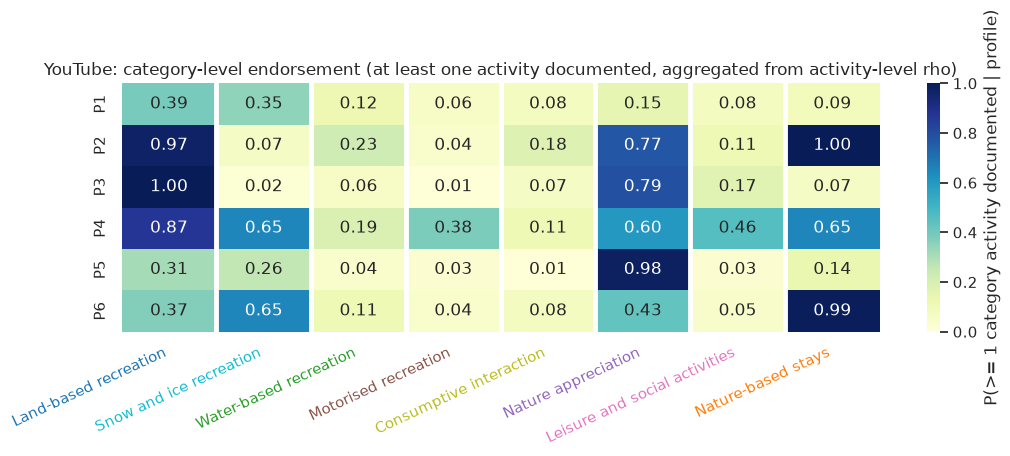

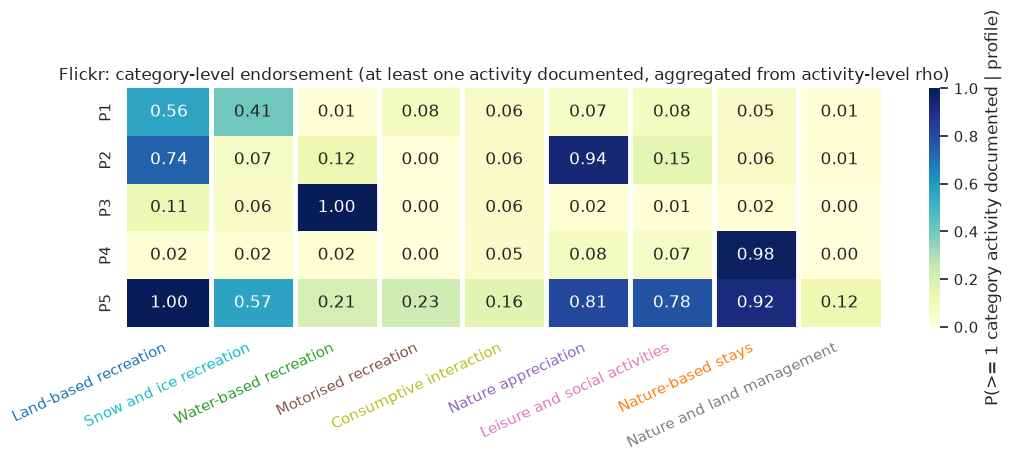

In [12]:
# Category-level aggregation of the profiles:
# P(at least one activity of the category documented | profile) = 1 - prod(1 - rho_a)
# over the category's activities in the model's restricted indicator set.
cat_endorse = {}
for name, res in [("YouTube", res_yt), ("Flickr", res_fl)]:
    rho = res["rho"]
    ce = pd.DataFrame(index=rho.index)
    for cat in CATEGORY_ORDER:
        acts = [a for a in activity_by_cat[cat] if a in rho.columns]
        if acts:
            ce[cat] = 1 - (1 - rho[acts]).prod(axis=1)
    cat_endorse[name] = ce
    fig, ax = plt.subplots(figsize=(11, 4.2))
    sns.heatmap(ce.round(2), annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax,
                cbar_kws={"label": "P(>= 1 category activity documented | profile)"})
    for b in range(1, len(ce.columns)):
        ax.axvline(b, color="white", lw=3.5)
    for tick in ax.get_xticklabels():
        tick.set_color(CATEGORY_PALETTE[tick.get_text()])
        tick.set_rotation(25)
        tick.set_ha("right")
    ax.set_title(f"{name}: category-level endorsement (at least one activity documented, "
                 "aggregated from activity-level rho)")
    ax.set_xlabel("")
    plt.tight_layout()
    plt.show()


In [13]:
# Substantive names assigned from the endorsed activities above (analyst interpretation)
PROFILE_NAMES = {
    "YouTube": {
        "P1": "General recreation (diffuse documentation)",
        "P2": "Walking-based camping & overnight trips",
        "P3": "Walking with nature observation & photography",
        "P4": "Winter walking, snow & cottage recreation",
        "P5": "Nature photography & observation",
        "P6": "Overnight camping & ski touring",
    },
    "Flickr": {
        "P1": "Walking & skiing",
        "P2": "Nature observation & photography walks",
        "P3": "Boating & water-based trips",
        "P4": "Camping & overnight stays",
        "P5": "Multi-activity trips (walking-based)",
    },
}
for name, res in [("YouTube", res_yt), ("Flickr", res_fl)]:
    print(f"{name}:")
    for p, nm in PROFILE_NAMES[name].items():
        print(f"  {p} ({res['shares'][p]:.1%}): {nm}")

YouTube:
  P1 (33.4%): General recreation (diffuse documentation)
  P2 (22.7%): Walking-based camping & overnight trips
  P3 (19.6%): Walking with nature observation & photography
  P4 (9.5%): Winter walking, snow & cottage recreation
  P5 (9.3%): Nature photography & observation
  P6 (5.4%): Overnight camping & ski touring
Flickr:
  P1 (37.7%): Walking & skiing
  P2 (28.8%): Nature observation & photography walks
  P3 (16.6%): Boating & water-based trips
  P4 (9.4%): Camping & overnight stays
  P5 (7.6%): Multi-activity trips (walking-based)


### Walking-focused follow-up (not a restriction)

Which profiles contain documented walking, and with what probability; the share of
episodes with documented walking per profile; and a compact co-occurrence analysis of
walking with the other activities (phi coefficients and conditional documentation
rates) as a descriptive complement. Had the LCA classes been unstable, MCA + clustering
or a plain co-occurrence analysis would have been the fallback; with stable,
interpretable classes they remain descriptive complements only.

In [14]:
def walking_followup(df_ind, res, keep, name):
    w = df_ind["Walking"]
    prev_w = w.mean()
    rho_w = res["rho"]["Walking"]
    # Hard-assignment share of walking episodes per profile (rank r -> P{r+1})
    pred_arr = np.asarray(res["pred"])
    share_walk = pd.Series(
        {f"P{r+1}": round(float(w.to_numpy()[pred_arr == r].mean()), 3)
         for r in range(len(res["shares"]))})
    # Consistency: modal-assignment shares must track rho (assignment bias is small here)
    assert np.abs(rho_w.to_numpy() - share_walk.to_numpy()).max() < 0.2,         f"{name}: walking shares inconsistent with rho"
    prof_walk = pd.DataFrame({"P(walking documented | profile)": rho_w.round(2),
                              "episodes with walking (share of profile)": share_walk})
    print(f"{name}: walking documented in {prev_w:.1%} of episodes overall")
    display(prof_walk)

    # Co-occurrence with walking: phi and conditional rate among walking episodes
    others = [a for a in keep if a != "Walking"]
    wv = df_ind["Walking"].to_numpy()
    rows = []
    for a in others:
        av = df_ind[a].to_numpy()
        phi = np.corrcoef(wv, av)[0, 1]
        rows.append({"activity": a,
                     "P(documented | walking episode)": round(av[wv == 1].mean(), 3),
                     "P(documented | other episodes)": round(av[wv == 0].mean(), 3),
                     "phi": round(phi, 3)})
    tab = pd.DataFrame(rows).sort_values("phi", ascending=False)
    display(tab.head(12))

walking_followup(df_yt_ind, res_yt, keep_yt, "YouTube")
walking_followup(df_fl_ind, res_fl, keep_fl, "Flickr")

YouTube: walking documented in 59.0% of episodes overall


,P(walking documented | profile),episodes with walking (share of profile)
P1,0.18,0.119
P2,0.95,0.962
P3,1.00,1.000
P4,0.85,0.899
P5,0.26,0.168
P6,0.23,0.127


,activity,P(documented | walking episode),P(documented | other episodes),phi
1,"Staying overnight in a tent, lodge, etc. in na...",0.402,0.125,0.300
0,Nature observation,0.565,0.263,0.299
2,Camping,0.381,0.124,0.283
13,Orienteering,0.088,0.018,0.146
14,Dog walking,0.080,0.018,0.135
3,Nature photography,0.292,0.186,0.121
18,Nature product collection,0.049,0.007,0.119
11,Outdoor activities with children,0.086,0.039,0.093
20,Picnicking,0.034,0.008,0.084
15,Travelling or staying in a caravan or camper,0.053,0.027,0.065


Flickr: walking documented in 47.8% of episodes overall


,P(walking documented | profile),episodes with walking (share of profile)
P1,0.48,0.486
P2,0.71,0.699
P3,0.11,0.116
P4,0.00,0.000
P5,1.00,1.000


,activity,P(documented | walking episode),P(documented | other episodes),phi
0,Nature observation,0.509,0.181,0.347
4,Outdoor activities with children,0.206,0.037,0.262
8,Dog walking,0.100,0.029,0.147
5,Nature photography,0.153,0.066,0.141
21,Orienteering,0.028,0.000,0.122
22,Guided tour,0.025,0.000,0.115
16,Climbing,0.038,0.006,0.111
18,Nature management,0.028,0.003,0.104
13,Picnicking,0.053,0.017,0.099
20,Skating,0.019,0.009,0.044


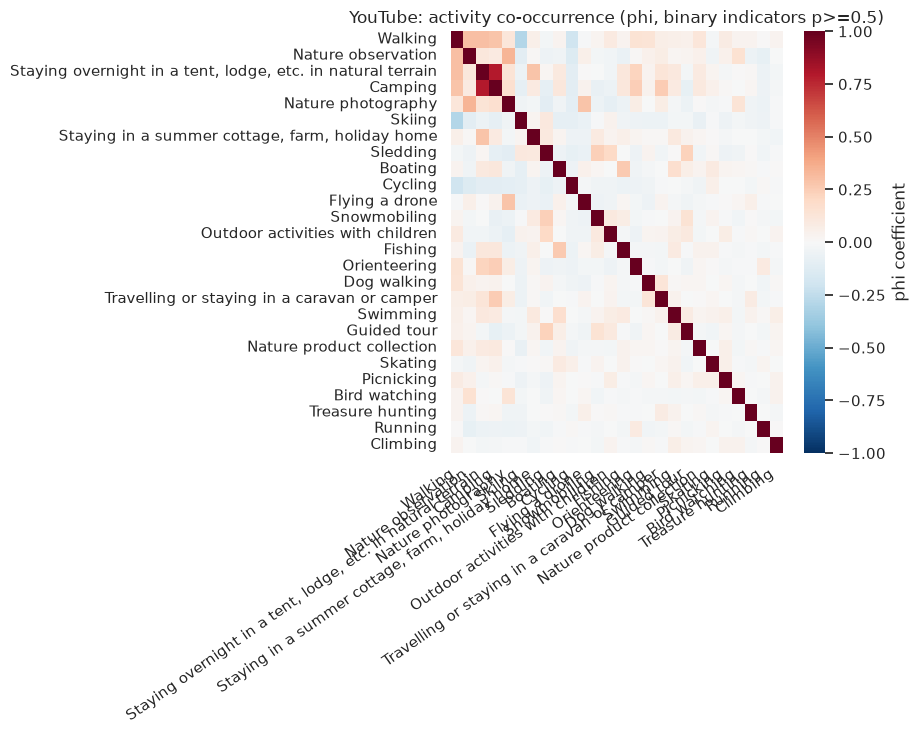

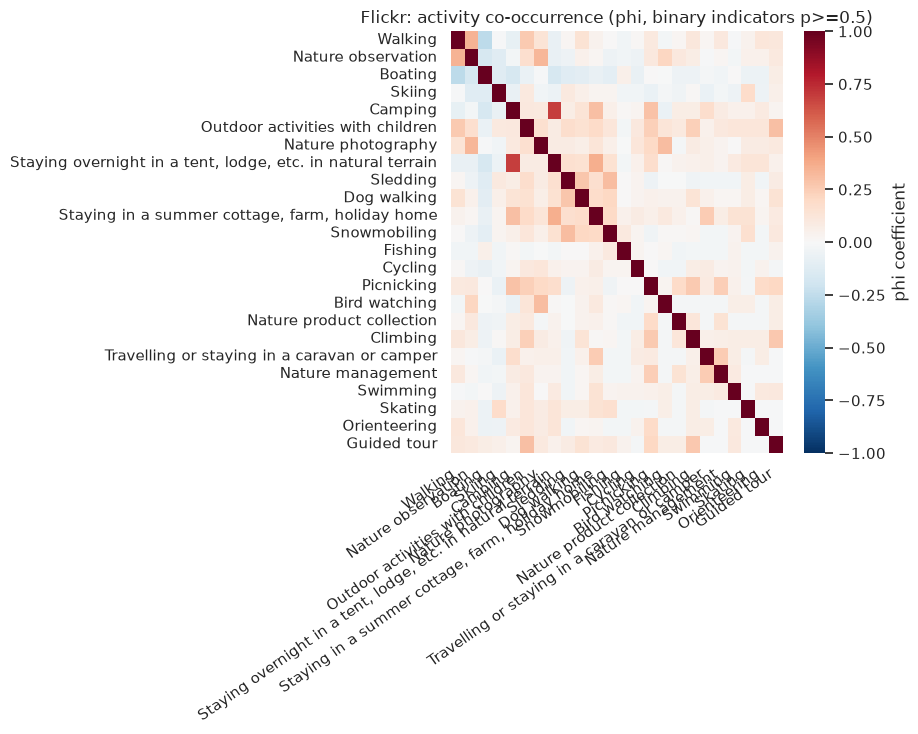

In [15]:
# Full activity co-occurrence (phi) heatmaps per source, restricted indicator sets
for name, df_ind, keep in [("YouTube", df_yt_ind, keep_yt), ("Flickr", df_fl_ind, keep_fl)]:
    phi = df_ind[keep].corr(method="pearson")
    fig, ax = plt.subplots(figsize=(9, 7.5))
    sns.heatmap(phi, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
                cbar_kws={"label": "phi coefficient"})
    ax.set_title(f"{name}: activity co-occurrence (phi, binary indicators p>=0.5)")
    plt.xticks(rotation=35, ha="right"); plt.yticks(rotation=0)
    plt.tight_layout(); plt.show()

## 5. Step 4 — YouTube vs Flickr comparison

**Caveat first.** The two models were fitted separately; their class indices are **not
comparable**. Profiles are matched across sources by their substantive
activity-probability structure: an optimal (Hungarian) matching on the Euclidean
distance between class rho vectors over the activity set common to both restricted
indicator sets.

In [16]:
common = sorted(set(keep_yt) & set(keep_fl))
rho_yt_c = res_yt["rho"][common].to_numpy()
rho_fl_c = res_fl["rho"][common].to_numpy()
D = pairwise_distances(rho_yt_c, rho_fl_c, metric="euclidean")
row_ind, col_ind = linear_sum_assignment(D)
matching = pd.DataFrame({"YouTube profile": [res_yt["rho"].index[i] for i in row_ind],
                         "Flickr profile": [res_fl["rho"].index[j] for j in col_ind],
                         "rho distance (common activities)": D[row_ind, col_ind].round(3)})
matching["YouTube profile"] = matching["YouTube profile"].map(PROFILE_NAMES["YouTube"])
matching["Flickr profile"] = matching["Flickr profile"].map(PROFILE_NAMES["Flickr"])
matching["YouTube prevalence"] = res_yt["shares"].iloc[row_ind].round(3).to_numpy()
matching["Flickr prevalence"] = res_fl["shares"].iloc[col_ind].round(3).to_numpy()
display(matching.sort_values("rho distance (common activities)"))

,YouTube profile,Flickr profile,rho distance (common activities),YouTube prevalence,Flickr prevalence
0,General recreation (diffuse documentation),Walking & skiing,0.363,0.334,0.377
2,Walking with nature observation & photography,Nature observation & photography walks,0.402,0.196,0.288
4,Overnight camping & ski touring,Camping & overnight stays,0.824,0.054,0.094
1,Walking-based camping & overnight trips,Multi-activity trips (walking-based),1.032,0.227,0.076
3,Nature photography & observation,Boating & water-based trips,1.526,0.093,0.166


YouTube                                                                                                                                    ...  \
   Boating Camping Dog walking Guided tour Nature observation Nature photography Outdoor activities with children Picnicking Skiing Sledding  ...   
P1    0.09    0.01        0.02        0.02               0.12               0.01                             0.05       0.01   0.25     0.11  ...   
P2    0.17    0.98        0.08        0.01               0.57               0.39                             0.05       0.03   0.01     0.02  ...   
P3    0.05    0.01        0.11        0.03               0.69               0.27                             0.06       0.07   0.00     0.01  ...   
P4    0.10    0.01        0.08        0.22               0.52               0.13                             0.29       0.00   0.18     0.57  ...   
P5    0.04    0.06        0.00        0.00               0.77               0.87                             0.00       0.01   0.23     0.00  ...   
P6    0.06    0.78        0.04        0.01               0.29               0.19                             0.00       0.02   0.50     0.27  ...   

               Flickr                                                                                              \
   Nature observation Nature photography Outdoor activities with children Picnicking Skiing Sledding Snowmobiling   
P1               0.05               0.02                             0.08       0.00   0.33     0.10         0.08   
P2               0.92               0.22                             0.12       0.03   0.05     0.02         0.00   
P3               0.01               0.01                             0.01       0.00   0.06     0.00         0.00   
P4               0.06               0.02                             0.03       0.03   0.00     0.02         0.00   
P5               0.62               0.44                             0.63       0.29   0.32     0.31         0.23   
P6                NaN                NaN                              NaN        NaN    NaN      NaN          NaN   

                                                                                                                        
   Staying in a summer cottage, farm, holiday home Staying overnight in a tent, lodge, etc. in natural terrain Walking  
P1                                            0.02                                               0.00             0.48  
P2                                            0.00                                               0.01             0.71  
P3                                            0.01                                               0.00             0.11  
P4                                            0.17                                               0.70             0.00  
P5                                            0.40                                               0.51             1.00  
P6                                             NaN                                                NaN              NaN  

[6 rows x 28 columns]

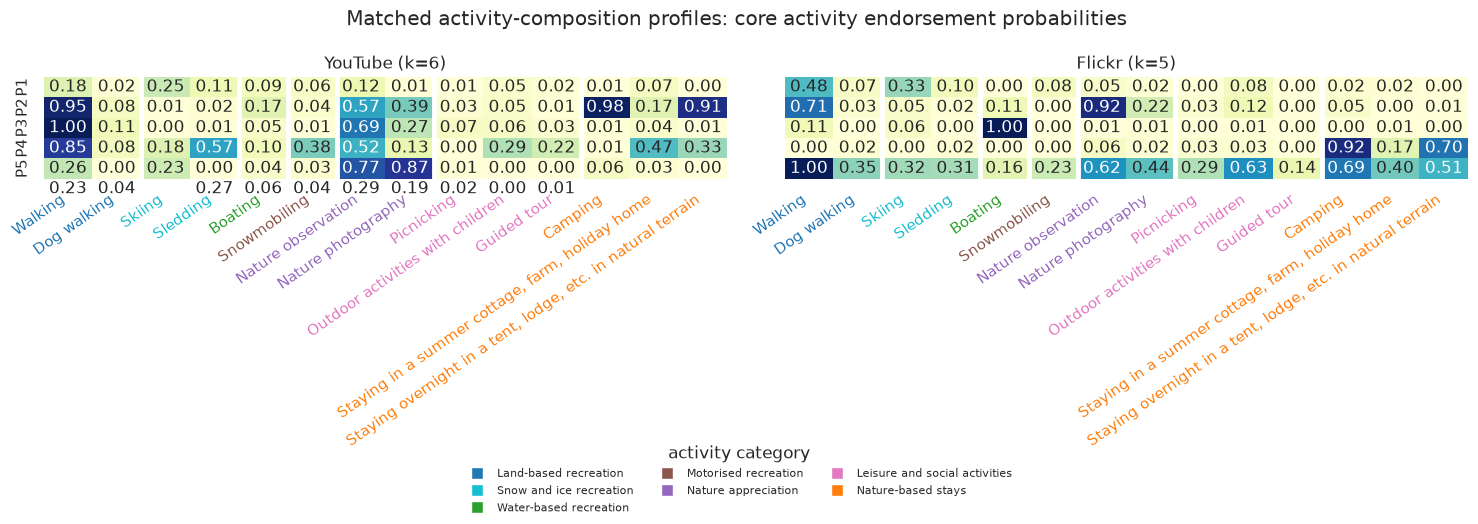

In [17]:
# Side-by-side: class-conditional endorsement probabilities of the matched profiles
# for the core activities (those endorsed >= 0.2 in at least one matched profile),
# columns grouped by activity category as in the profile heatmaps
core = sorted({a for a in common
               if (res_yt["rho"][a].max() >= 0.2) or (res_fl["rho"][a].max() >= 0.2)})
ordered_core, core_cats = grouped_columns(core)
side = pd.concat({"YouTube": res_yt["rho"][core], "Flickr": res_fl["rho"][core]}, axis=1).round(2)
display(side)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True)
for ax, (name, res) in zip(axes, [("YouTube", res_yt), ("Flickr", res_fl)]):
    sns.heatmap(res["rho"][ordered_core], annot=True, fmt=".2f", cmap="YlGnBu", vmin=0,
                vmax=1, ax=ax, cbar=False)
    for b in range(1, len(ordered_core)):
        if core_cats[b] != core_cats[b - 1]:
            ax.axvline(b, color="white", lw=3.5)
    for tick, cat in zip(ax.get_xticklabels(), core_cats):
        tick.set_color(CATEGORY_PALETTE[cat])
        tick.set_rotation(35)
        tick.set_ha("right")
    ax.set_title(f"{name} (k={res['rho'].shape[0]})")
    ax.set_xlabel("")
handles = [plt.Line2D([0], [0], marker="s", color="w", markerfacecolor=CATEGORY_PALETTE[cat],
                      markersize=9, label=cat) for cat in CATEGORY_ORDER if cat in set(core_cats)]
fig.legend(handles=handles, loc="lower center", ncols=3, fontsize=8, frameon=False,
           title="activity category")
plt.suptitle("Matched activity-composition profiles: core activity endorsement probabilities")
plt.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()


,YouTube,Flickr
Walking,0.590,0.478
Nature observation,0.442,0.338
"Staying overnight in a tent, lodge, etc. in natural terrain",0.288,0.106
Camping,0.276,0.161
Nature photography,0.249,0.108
Skiing,0.150,0.175
"Staying in a summer cottage, farm, holiday home",0.149,0.055
Sledding,0.114,0.067
Boating,0.095,0.211
Cycling,0.089,0.042


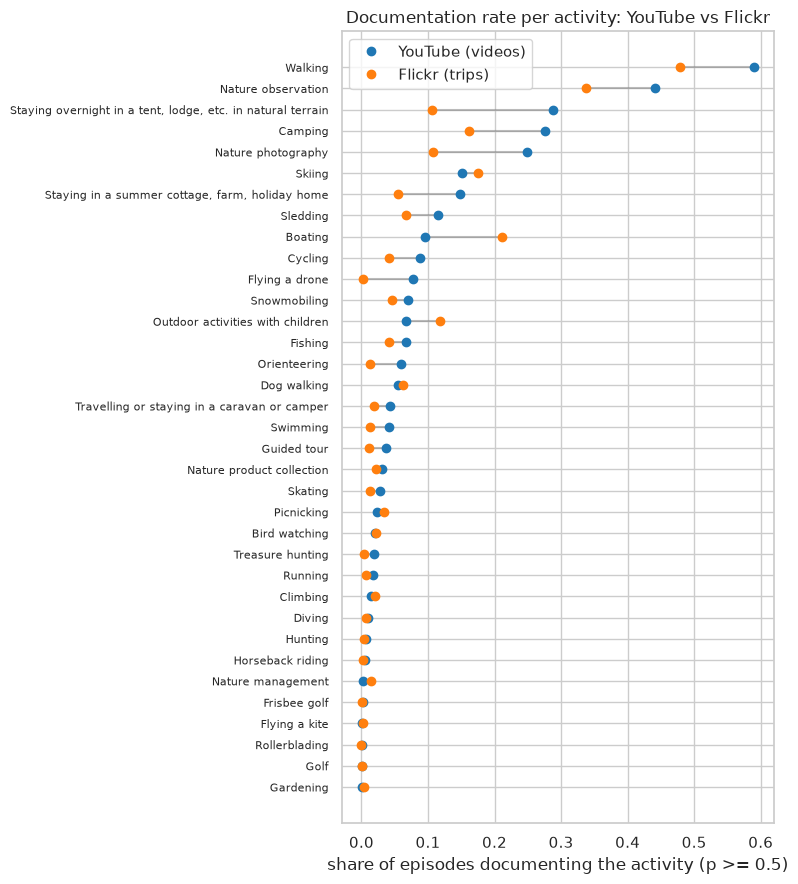

Activities concentrated in one source stand out as horizontal gaps, e.g. overnight stays / camping vs others.


In [18]:
# Activity-level comparison: documentation rate per activity, YouTube vs Flickr (all 35)
cmp = pd.DataFrame({"YouTube": (df_yt_probs >= THRESHOLD).mean(),
                    "Flickr": (df_fl_probs >= THRESHOLD).mean()}).sort_values("YouTube", ascending=False)
display(cmp.round(3).head(15))
fig, ax = plt.subplots(figsize=(8, 9))
y = np.arange(len(cmp))[::-1]
ax.hlines(y, cmp["Flickr"], cmp["YouTube"], color="gray", alpha=0.5)
ax.plot(cmp["YouTube"], y, "o", color="tab:blue", label="YouTube (videos)")
ax.plot(cmp["Flickr"], y, "o", color="tab:orange", label="Flickr (trips)")
ax.set_yticks(y); ax.set_yticklabels(cmp.index, fontsize=8)
ax.set_xlabel("share of episodes documenting the activity (p >= 0.5)")
ax.set_title("Documentation rate per activity: YouTube vs Flickr")
ax.legend(); plt.tight_layout(); plt.show()
print("Activities concentrated in one source stand out as horizontal gaps, e.g. overnight stays / camping vs others.")

## 6. Bridging Level 2 profiles back to the LVVI3 main-activity view

The survey and social media answer asymmetric questions: the survey records a
*self-reported single main activity*, while social media records a *documented
(selected, incomplete) activity composition*. The two exhibits below bridge the levels
**distributionally** — they do not assume either source is a complete account of the
trips.

**a. Profile → survey-style main-activity crosswalk.** For each profile, the
survey-analog main activity is the activity with the highest class-conditional
endorsement probability (ρ); the remaining strongly endorsed activities show what lies
*beyond the main activity* — the content a single-main-activity survey could not
reveal.

**b. Walking-argmax episodes: what else is documented.** Using the per-episode
probability matrices retained in Step 2, each episode's survey-analog main activity is
its argmax-probability activity. Among episodes a survey would have called "Walking",
we report the rates at which other activities are also documented (binary indicators at
the 0.5 convention).

In [19]:
def profile_crosswalk(res, name):
    """Profile -> survey-analog main activity (argmax rho) plus the other strongly endorsed activities."""
    rho = res["rho"]
    rows = []
    for p in rho.index:
        r = rho.loc[p]
        analog = r.idxmax()
        others = r.drop(labels=[analog])
        others = others[others >= 0.10].sort_values(ascending=False)
        rows.append({"profile": f"{p} — {PROFILE_NAMES[name][p]}",
                     "prevalence": round(res["shares"][p], 3),
                     "survey-analog main activity": analog,
                     "also endorsed (rho >= 0.10)": ", ".join(
                         f"{a} ({v:.2f})" for a, v in others.items())})
    return pd.DataFrame(rows)

print("a. Profile -> survey-style main-activity crosswalk")
display(profile_crosswalk(res_yt, "YouTube"))
display(profile_crosswalk(res_fl, "Flickr"))

a. Profile -> survey-style main-activity crosswalk


,profile,prevalence,survey-analog main activity,also endorsed (rho >= 0.10)
0,P1 — General recreation (diffuse documentation),0.334,Skiing,"Cycling (0.19), Walking (0.18), Nature observa..."
1,P2 — Walking-based camping & overnight trips,0.227,Camping,"Walking (0.95), Staying overnight in a tent, l..."
2,P3 — Walking with nature observation & photogr...,0.196,Walking,"Nature observation (0.69), Nature photography ..."
3,"P4 — Winter walking, snow & cottage recreation",0.095,Walking,"Sledding (0.57), Nature observation (0.52), St..."
4,P5 — Nature photography & observation,0.093,Nature photography,"Nature observation (0.77), Flying a drone (0.3..."
5,P6 — Overnight camping & ski touring,0.054,"Staying overnight in a tent, lodge, etc. in na...","Camping (0.78), Staying in a summer cottage, f..."


,profile,prevalence,survey-analog main activity,also endorsed (rho >= 0.10)
0,P1 — Walking & skiing,0.377,Walking,Skiing (0.33)
1,P2 — Nature observation & photography walks,0.288,Nature observation,"Walking (0.71), Nature photography (0.22), Out..."
2,P3 — Boating & water-based trips,0.166,Boating,Walking (0.11)
3,P4 — Camping & overnight stays,0.094,Camping,"Staying overnight in a tent, lodge, etc. in na..."
4,P5 — Multi-activity trips (walking-based),0.076,Walking,"Camping (0.69), Outdoor activities with childr..."


b. Episodes whose survey-analog main activity is Walking: what else is documented
YouTube: Walking-argmax episodes: 1357 of 3745 (36.2%)


,share of Walking-argmax episodes documenting it
Nature observation,0.604
"Staying overnight in a tent, lodge, etc. in natural terrain",0.357
Camping,0.354
Nature photography,0.314
"Staying in a summer cottage, farm, holiday home",0.123
Orienteering,0.110
Dog walking,0.068
Flying a drone,0.061
Outdoor activities with children,0.055
Sledding,0.050


Flickr: Walking-argmax episodes: 197 of 669 (29.4%)


,share of Walking-argmax episodes documenting it
Nature observation,0.533
Outdoor activities with children,0.147
Nature photography,0.091
Camping,0.076
Dog walking,0.071
Boating,0.056
Picnicking,0.051
Skiing,0.046
Climbing,0.030
Guided tour,0.025


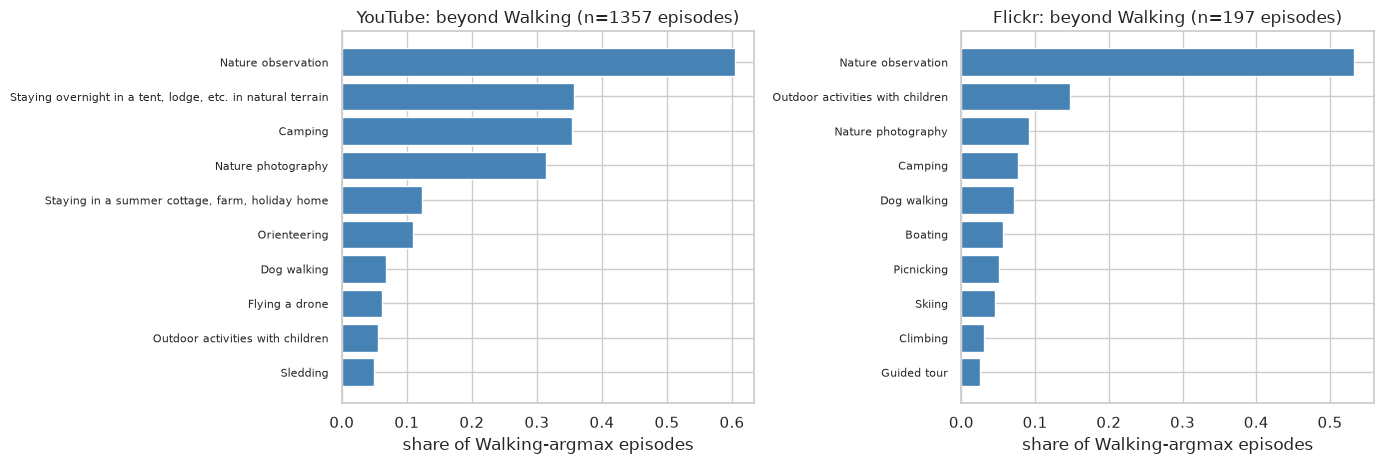

In [20]:
print("b. Episodes whose survey-analog main activity is Walking: what else is documented")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharex=False)
for ax, (name, df_p) in zip(axes, [("YouTube", df_yt_probs), ("Flickr", df_fl_probs)]):
    argmax_act = df_p.idxmax(axis=1)
    walk_eps = argmax_act == "Walking"
    print(f"{name}: Walking-argmax episodes: {walk_eps.sum()} of {len(df_p)} "
          f"({walk_eps.mean():.1%})")
    rates = ((df_p.loc[walk_eps] >= THRESHOLD).mean()
             .drop("Walking").sort_values(ascending=False))
    tab = pd.DataFrame({"share of Walking-argmax episodes documenting it": rates.round(3)})
    display(tab.head(10))
    top = rates.head(10).iloc[::-1]
    ax.barh(top.index, top.values, color="steelblue")
    ax.set_title(f"{name}: beyond Walking (n={walk_eps.sum()} episodes)")
    ax.set_xlabel("share of Walking-argmax episodes")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()


## 7. Step 5 — Spatial and temporal patterns

Metadata joins: YouTube per-video dates (`year_month` / `published_at` month) and area
flags come from `youtube_clef_videos_wide.csv` (geometry stored as WKT, EPSG:3067 —
parsed with shapely). Flickr trips already carry `trip_start` / `trip_end` (actual trip
dates, *date_taken* basis) and area flags and geometry from `flickr_trips.gpkg`.

- **Season** (meteorological): Winter Dec–Feb, Spring Mar–May, Summer Jun–Aug, Autumn
  Sep–Nov. Flickr uses the `trip_start` month; YouTube uses the **upload** month with
  the explicit caveat that *upload date ≠ trip date*.
- **Destination type**: an episode can intersect several area types, so the four flags
  (national park / nature reserve / wilderness area / commercial forest) are treated
  **independently** (share of a profile's episodes located in each type), not as a
  mutually exclusive primary type.

**Caveat.** Social media shows where *documented content* was produced, not the
distribution of all recreational use.

In [21]:
# --- YouTube metadata ---
df_meta_yt = pd.read_csv(f"{DATA}/YouTube/clef_labels/youtube_clef_videos_wide.csv",
                         usecols=["video_id", "datetime", "year", "month", "year_month"] + AREA_FLAGS + ["geometry"])
df_meta_yt = df_meta_yt.set_index("video_id").reindex(df_yt_ind.index)
assert df_meta_yt["month"].notna().all()
for c in AREA_FLAGS:
    df_meta_yt[c] = df_meta_yt[c].astype(int)
gdf_yt = gpd.GeoDataFrame(
    df_meta_yt, geometry=df_meta_yt["geometry"].map(lambda s: shapely.wkt.loads(s) if pd.notna(s) else None),
    crs="EPSG:3067")

# --- Flickr metadata (one row per trip; flags stored as '0'/'1' strings) ---
trip_meta = gdf_trips.drop_duplicates("trip_id").set_index("trip_id").reindex(df_fl_ind.index)
trip_meta[AREA_FLAGS] = trip_meta[AREA_FLAGS].astype(int)
trip_meta["trip_start"] = pd.to_datetime(trip_meta["trip_start"])
gdf_fl = gpd.GeoDataFrame(trip_meta, geometry="geometry", crs=gdf_trips.crs)

# --- season ---
gdf_yt["season"] = gdf_yt["month"].map(SEASONS)          # upload month (caveat: upload != trip date)
gdf_fl["season"] = gdf_fl["trip_start"].dt.month.map(SEASONS)   # actual trip month
print(f"YouTube episodes with geometry: {gdf_yt.geometry.notna().sum()} / {len(gdf_yt)}")
print(f"Flickr episodes with geometry: {gdf_fl.geometry.notna().sum()} / {len(gdf_fl)}")

YouTube episodes with geometry: 3745 / 3745
Flickr episodes with geometry: 669 / 669


YouTube: profile share within each season (columns sum to 1)


season,Spring,Summer,Autumn,Winter
P1 (General recreation (diffuse documentation)),0.396,0.303,0.254,0.322
P2 (Walking-based camping & overnight trips),0.170,0.279,0.297,0.183
P3 (Walking with nature observation & photography),0.174,0.281,0.283,0.192
"P4 (Winter walking, snow & cottage recreation)",0.103,0.050,0.045,0.151
P5 (Nature photography & observation),0.082,0.056,0.094,0.084
P6 (Overnight camping & ski touring),0.075,0.030,0.026,0.068


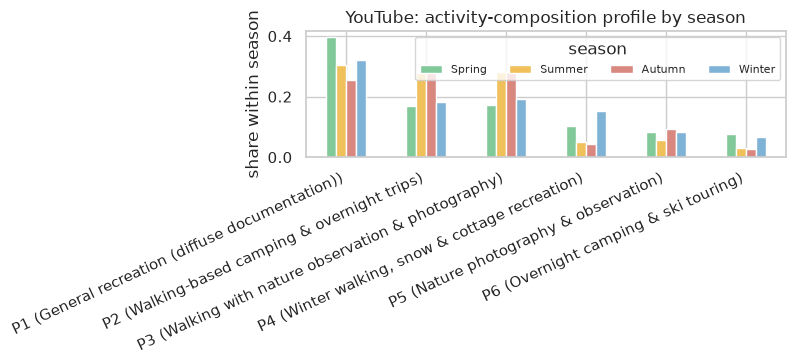

Flickr: profile share within each season (columns sum to 1)


season,Spring,Summer,Autumn,Winter
P1 (Walking & skiing),0.390,0.229,0.262,0.636
P2 (Nature observation & photography walks),0.235,0.342,0.405,0.176
P3 (Boating & water-based trips),0.154,0.264,0.183,0.040
P4 (Camping & overnight stays),0.140,0.087,0.079,0.080
P5 (Multi-activity trips (walking-based)),0.081,0.078,0.071,0.068


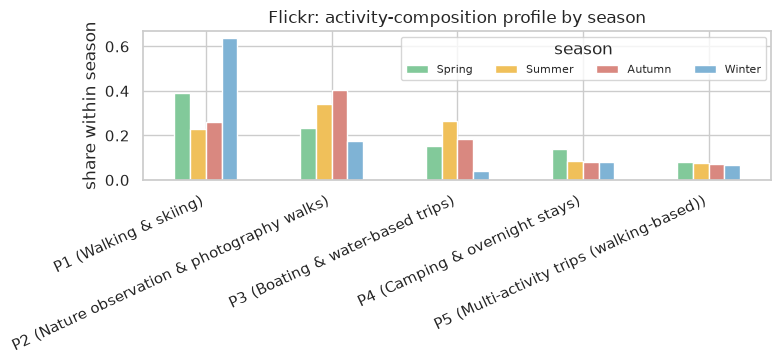

In [22]:
# Profile x season (column-normalized), per source
for name, gdf, res in [("YouTube", gdf_yt, res_yt), ("Flickr", gdf_fl, res_fl)]:
    pred_s = pd.Series(res["pred"], index=gdf.index, name="profile")
    tab = pd.crosstab(pred_s.map(lambda c: f"P{c+1}"), gdf["season"], normalize="columns").reindex(
        columns=SEASON_ORDER, fill_value=0).round(3)
    tab.index = [f"{i} ({PROFILE_NAMES[name][i]})" for i in tab.index]
    print(f"{name}: profile share within each season (columns sum to 1)")
    display(tab)
    fig, ax = plt.subplots(figsize=(8, 3.8))
    tab.plot.bar(ax=ax, color={"Winter": "#7fb3d5", "Spring": "#82c99a",
                               "Summer": "#f0c05a", "Autumn": "#d98880"})
    ax.set_ylabel("share within season"); ax.set_xlabel("")
    ax.set_title(f"{name}: activity-composition profile by season")
    plt.xticks(rotation=25, ha="right"); plt.legend(title="season", ncols=4, fontsize=8)
    plt.tight_layout(); plt.show()

YouTube: share of profile episodes located in each area type (flags independent)


,n,prevalence,National park,Nature reserve,Wilderness area,Commercial forest
P1 (General recreation (diffuse documentation)),1198,0.334,0.321,0.355,0.048,0.520
P2 (Walking-based camping & overnight trips),861,0.227,0.516,0.562,0.178,0.186
P3 (Walking with nature observation & photography),864,0.196,0.519,0.584,0.059,0.266
"P4 (Winter walking, snow & cottage recreation)",336,0.095,0.086,0.089,0.006,0.848
P5 (Nature photography & observation),297,0.093,0.478,0.515,0.108,0.306
P6 (Overnight camping & ski touring),189,0.054,0.423,0.466,0.122,0.365


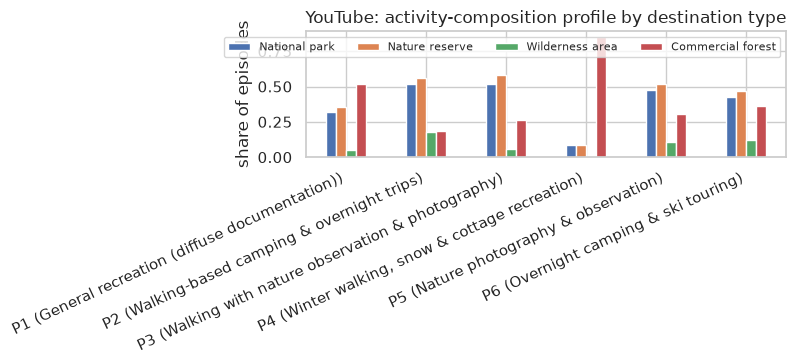

Flickr: share of profile episodes located in each area type (flags independent)


,n,prevalence,National park,Nature reserve,Wilderness area,Commercial forest
P1 (Walking & skiing),251,0.377,0.243,0.327,0.028,0.466
P2 (Nature observation & photography walks),193,0.288,0.513,0.611,0.021,0.202
P3 (Boating & water-based trips),112,0.166,0.062,0.125,0.000,0.071
P4 (Camping & overnight stays),63,0.094,0.397,0.476,0.095,0.317
P5 (Multi-activity trips (walking-based)),50,0.076,0.340,0.420,0.060,0.540


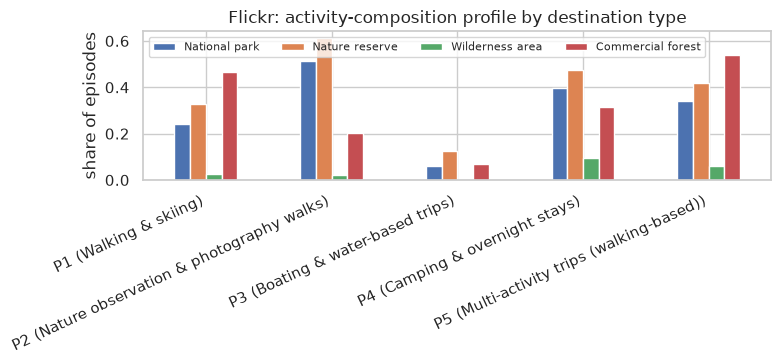

In [23]:
# Profile x destination type (flags treated independently: share of profile episodes with flag = 1)
for name, gdf, res in [("YouTube", gdf_yt, res_yt), ("Flickr", gdf_fl, res_fl)]:
    pred_s = pd.Series(res["pred"], index=gdf.index, name="profile")
    rows = []
    for c in sorted(set(res["pred"])):
        sub = gdf[pred_s == c]
        row = {"profile": f"P{c+1}", "n": len(sub),
               "prevalence": round(res["shares"][f"P{c+1}"], 3)}
        for f_ in AREA_FLAGS:
            row[AREA_LABELS[f_]] = round(sub[f_].mean(), 3)
        rows.append(row)
    tab = pd.DataFrame(rows).set_index("profile")
    tab.index = [f"{i} ({PROFILE_NAMES[name][i]})" for i in tab.index]
    print(f"{name}: share of profile episodes located in each area type (flags independent)")
    display(tab)
    fig, ax = plt.subplots(figsize=(8, 3.8))
    tab[ list(AREA_LABELS.values()) ].plot.bar(ax=ax)
    ax.set_ylabel("share of episodes"); ax.set_xlabel("")
    ax.set_title(f"{name}: activity-composition profile by destination type")
    plt.xticks(rotation=25, ha="right"); plt.legend(ncol=4, fontsize=8)
    plt.tight_layout(); plt.show()

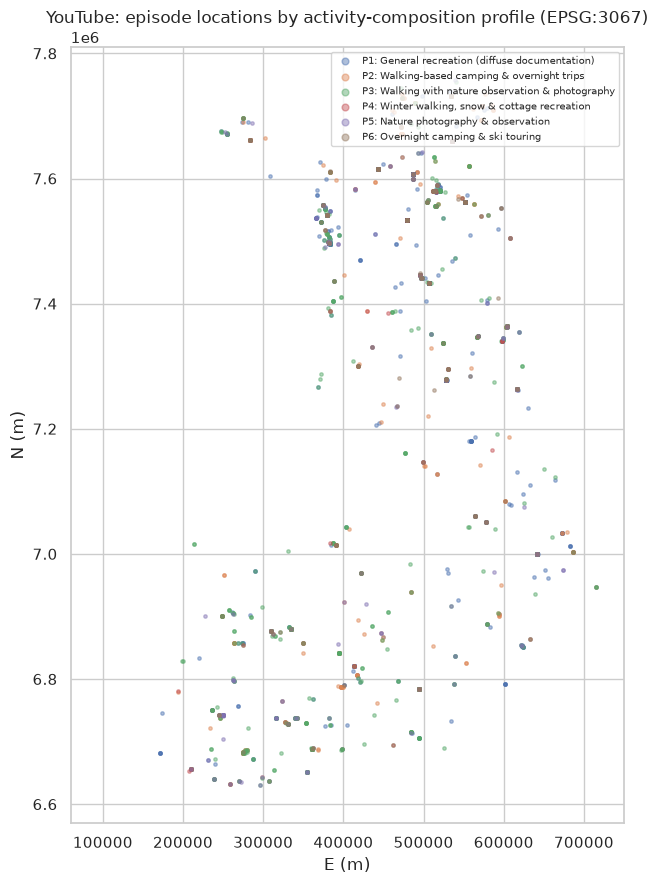

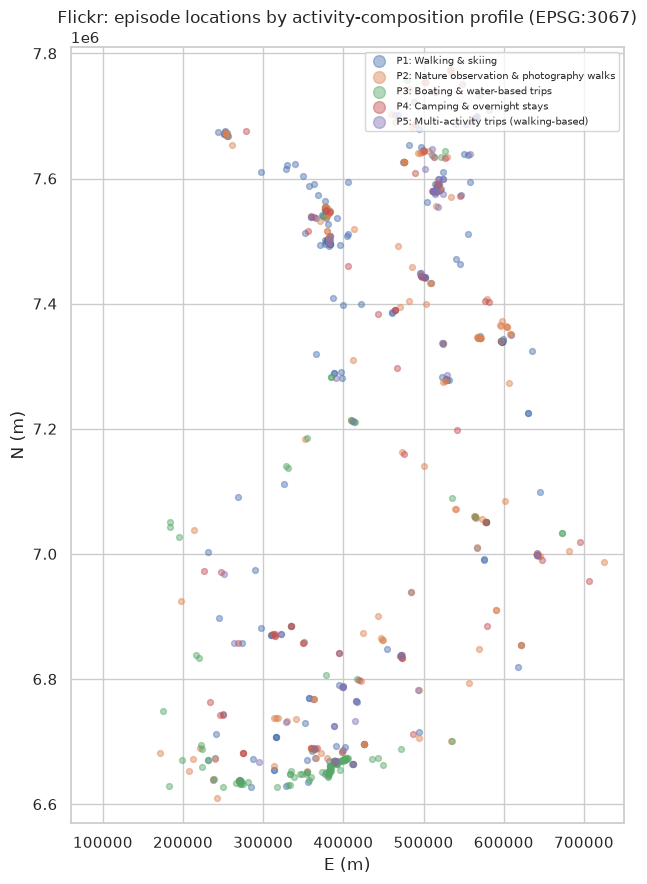

In [24]:
# Maps of episode locations colored by profile (EPSG:3067, basemap-free)
FIN_EXTENT = (60000, 750000, 6570000, 7810000)
for name, gdf, res in [("YouTube", gdf_yt, res_yt), ("Flickr", gdf_fl, res_fl)]:
    pred_s = pd.Series(res["pred"], index=gdf.index)
    fig, ax = plt.subplots(figsize=(6.5, 9))
    for c in sorted(set(res["pred"])):
        sub = gdf[pred_s == c]
        sub.plot(ax=ax, markersize=6 if name == "YouTube" else 18, alpha=0.45,
                 label=f"P{c+1}: {PROFILE_NAMES[name][f'P{c+1}']}", aspect=None)
    ax.set_xlim(FIN_EXTENT[0], FIN_EXTENT[1]); ax.set_ylim(FIN_EXTENT[2], FIN_EXTENT[3])
    ax.set_xlabel("E (m)"); ax.set_ylabel("N (m)")
    ax.set_title(f"{name}: episode locations by activity-composition profile (EPSG:3067)")
    ax.legend(fontsize=7, loc="upper right", markerscale=2)
    plt.tight_layout(); plt.show()

## 8. Step 6 — Summary of findings

**Level 1 — LVVI3 survey (reported main activity, descriptive).** Walking dominates the
reported main activities (48.6% unweighted, 47.7% weighted of 451 trips), far ahead of
skiing (8.9%), then dog walking (5.5%), fishing (5.1%) and cycling (3.8%). A single main
activity per trip cannot reveal what else a trip involved — which motivated Level 2.

**Level 2 — documented activity composition (Clef indicators at p ≥ 0.5).**
- Episodes: 3,745 YouTube videos (3.1 documented activities/video; 4.0% videos with no
  activity ≥ 0.5) and 669 Flickr trips (trip-level max photo probability; 2.2
  activities/trip; 0% with no evidence). Restricted LCA indicator sets: 26 activities
  (YouTube) and 24 (Flickr), each documented in ≥ 1% of episodes. Threshold sensitivity
  (0.3/0.5/0.7) changes activity counts roughly linearly and raises the zero-evidence
  share at 0.7 (YouTube 14.7%, Flickr 27.8%), without altering the qualitative design.
- **YouTube, k = 6** (BIC 51,571; entropy R² = 0.84; all classes ≥ 5.4%): P1 general
  recreation — diffuse documentation (33.4%); P2 walking-based camping & overnight trips
  (22.7%; camping 0.98, walking 0.95, tent 0.91); P3 walking with nature observation &
  photography (19.6%; walking 1.00); P4 winter walking, snow & cottage recreation
  (9.5%; sledding 0.57, snowmobiling 0.38, cottage 0.47); P5 nature photography &
  observation (9.3%; photography 0.87); P6 overnight camping & ski touring (5.4%).
- **Flickr, k = 5** (BIC 7,603 — the BIC minimum; entropy R² = 0.90; all classes ≥ 7.6%):
  P1 walking & skiing (37.7%); P2 nature observation & photography walks (28.8%;
  observation 0.92); P3 boating & water-based trips (16.6%; boating 1.00); P4 camping &
  overnight stays (9.4%; camping 0.92); P5 multi-activity walking-based trips (7.6%).

**Walking.** Documented in 59.0% of YouTube episodes and 47.8% of Flickr trips. In
YouTube it is near-universal in P2–P4 (rho 0.85–1.00) and diffuse in P1/P5/P6; walking
episodes co-document overnight tent stays (phi 0.30), nature observation (0.30) and
camping (0.28). In Flickr, walking structures P1 (0.48), P2 (0.71) and the multi-activity
P5 (1.00); its strongest co-documentation is with nature observation (phi 0.35) and
outdoor activities with children (0.26).

**Cross-source comparison.** Hungarian matching on class rho vectors pairs, e.g.,
YouTube P3 with Flickr P2 (walking-centred observation/photography) and YouTube P1 with
Flickr P1. Activity documentation differs by source: overnight tent stays (YouTube 28.8%
vs Flickr 10.6%), cottage stays (14.9% vs 5.5%) and drone flying (7.7% vs 0.3%) are
YouTube-concentrated, while boating (9.5% vs 21.1%) is Flickr-concentrated — consistent
with videos documenting overnight/winter expeditions and photos documenting water-based
day trips.

**Spatial and temporal patterns (documented content, not all recreational use).**
YouTube seasonality uses upload month (≠ trip date); Flickr uses actual trip month.
YouTube P4 (winter snow & cottage) peaks in winter (15.1% of winter episodes vs 3–5% in
summer/autumn) and is concentrated in commercial forests (84.8%); Flickr P1 (walking &
skiing) is strongly winter-peaked (63.6% of winter trips), and Flickr P3 (boating)
peaks in summer. Park-oriented profiles (YouTube P2/P3/P5, Flickr P2/P4) lie mostly in
national parks and nature reserves (40–60%), while boating trips rarely do.

**Caveats.** Profiles describe *documented* activity composition from social media and a
*reported main activity* from the survey; neither is a complete account of the trips.
Separately fitted models mean class indices are comparable only through profile
matching, and upload dates proxy trip dates on YouTube.
**Bridging back to the survey main-activity view (distributional, not a complete account).**
- *Profile → survey-analog main activity:* YouTube profiles map to Skiing (P1), Camping
  (P2), Walking (P3, P4), Nature photography (P5) and overnight tent stays (P6); Flickr
  profiles map to Walking (P1, P5), Nature observation (P2), Boating (P3) and Camping
  (P4). Every profile endorses further activities at ρ ≥ 0.10 beyond its analog main
  activity (e.g. the YouTube camping profile also endorses walking 0.95 and overnight
  tent stays 0.91) — the content a single-main-activity survey could not reveal.
- *Walking-argmax episodes:* 1,357 of 3,745 YouTube episodes (36.2%) and 197 of 669
  Flickr trips (29.4%) have Walking as their argmax-probability activity. Among these,
  YouTube also documents nature observation (60.4%), overnight tent stays (35.7%),
  camping (35.4%) and nature photography (31.4%); Flickr also documents nature
  observation (53.3%), outdoor activities with children (14.7%) and nature photography
  (9.1%).
